In [27]:
import pandas as pd
import numpy as np

df = pd.read_csv('cause_death.csv')
df.head()

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...


In [28]:
df.dtypes

Cause              object
Type               object
Year                int64
Data Redundancy     int64
Total Deaths        int64
Source             object
Page at Source     object
Source URL         object
dtype: object

In [29]:
df.fillna(0)
df.drop_duplicates()

q1 = df["Total Deaths"].quantile(0.25)
q3 = df["Total Deaths"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr 
upper = q3 + 1.5 * iqr 

df_clean = df[(df["Total Deaths"] >= lower) & (df["Total Deaths"] <= upper)]

print(f"Data sebelum cleaning : {len(df)}")
print(f"Data sesudah cleaning : {len(df_clean)}")

Data sebelum cleaning : 680
Data sesudah cleaning : 552


In [30]:
# 1. Uji Shapiro-Wilk untuk normalitas

from scipy import stats

shapiro_test = stats.shapiro(df_clean['Total Deaths'])
print("Hasil Uji Shapiro-Wilk")
print("Statistik : ", shapiro_test.statistic)
print("P-Value : ", shapiro_test.pvalue)

Hasil Uji Shapiro-Wilk
Statistik :  0.5902771802575988
P-Value :  4.714403494882831e-34


In [31]:
# 2. Korelasi Pearson

from scipy import stats

correlation, p_value = stats.pearsonr(df_clean["Year"], df_clean["Total Deaths"])

print(f"Korelasi antara Year dan Total Deaths: {correlation}")
print(f"P-value: {p_value}")


Korelasi antara Year dan Total Deaths: -0.10708174138273542
P-value: 0.011822788193798232


In [49]:
df_clean["Year"].sort_values()

1      2000
641    2000
39     2000
393    2000
360    2001
       ... 
87     2021
609    2021
634    2021
22     2021
679    2021
Name: Year, Length: 552, dtype: int64

In [50]:
# 2. Korelasi Spearman

from scipy import stats

df_group = df_clean.groupby("Year")["Total Deaths"].sum()

spearman_year = stats.spearmanr(df_group.index, df_group.values)
print(f"Korelasi antara Year dan Total Deaths : ")
print(f"Statistik : {spearman_year.statistic}")
print(f"P-value: {spearman_year.pvalue}")


Korelasi antara Year dan Total Deaths : 
Statistik : 0.12140033879164315
P-value: 0.5904546067875798


In [44]:
from scipy.stats import kendalltau

# Korelasi Kendall Tau
kendall_year = kendalltau(df_group.index, df_group.values)
print(f"Korelasi antara Year dan Total Deaths : ")
print(f"Statistik : {kendall_year.statistic}")
print(f"P-value: {kendall_year.pvalue}")


Korelasi antara Year dan Total Deaths : 
Statistik : 0.10822510822510822
P-value: 0.5030535233842987


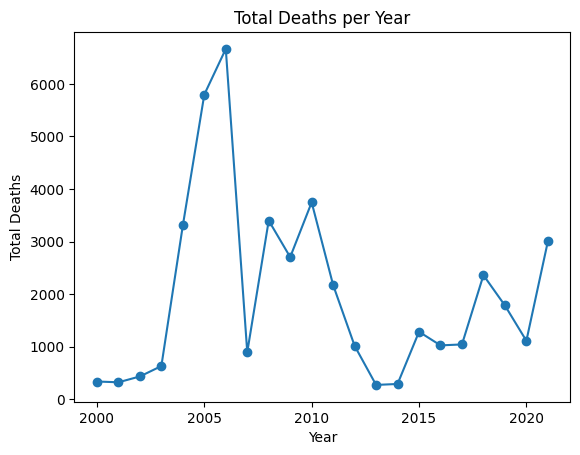

In [45]:
import matplotlib.pyplot as plt

# Plot Total Deaths per Year
plt.plot(df_group.index, df_group.values, marker='o')
plt.xlabel("Year")
plt.ylabel("Total Deaths")
plt.title("Total Deaths per Year")
plt.show()
